# 20261112 - Parallel Distribution

### What does this mean? *(Copied from distributed memory parallelism notes)*
1. We should reduce the total amount of communications necessary (*not* necessarily require less data communicated)
    - Choose algorithms that are *communication avoiding*
    - Remove any unnecessary communications, particularly in "hot loops"
   

2. We should "hide" the latency if we can
    - Overlap communication with other useful work
    - Computing while communicating
    - Batching communication together (where it makes sense)

## Advice from Bill Gropp (father of MPI)

>   You want to think about how you decompose your data structures, how
    you think about them globally.  [...]  If you were building a house,
    you'd start with a set of blueprints that give you a picture of what
    the whole house looks like.  You wouldn't start with a bunch of
    tiles and say. "Well I'll put this tile down on the ground, and
    then I'll find a tile to go next to it."  But all too many people
    try to build their parallel programs by creating the smallest
    possible tiles and then trying to have the structure of their code
    emerge from the chaos of all these little pieces.  You have to have
    an organizing principle if you're going to survive making your code
    parallel.
    -- https://www.rce-cast.com/Podcast/rce-28-mpich2.html

- Distributed-memory parallelism lives and dies by how you distribute the memory (duh)
- Often needs to be done at an architectural level
    - Can't really start piece-by-piece
    - Difficult to take a shared memory code and make an **optimal** MPI/distributed memory program without significant modifications

## How do we want to distribute our problem across multiple ranks?
Two goals:
- Distribute the total computation evenly across processors
    - We're only as fast as the slowest process
- Minimize communication as much as possible
    - Both in number of communciation and amount of data to be communicated

### Simplest example: Sparse matrix-vector multiply

Say we have a (sparse) matrix that we want to have distributed across ranks.
- How should we distribute the matrix?
- How should we distribute the vector?

Easiest way is to parallelize by
- Assigning rows of the vector and matrix to each rank
- Each rank holds the matrix entries for those rows
![dense matvec parallel](../img/05-matvec-row-dense.png)

See [step-by-step workout of how the mat-vec product happens](https://www.sandia.gov/app/uploads/sites/197/2022/06/CS591MH_20070913.pdf)

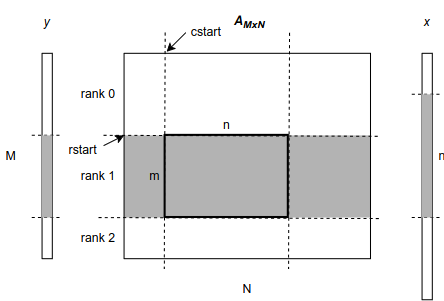

from [*Verification Challenges in Sparse Matrix Vector
Multiplication in High Performance Computing: Part I*](https://arxiv.org/pdf/2510.13427v1)

### Example matrix
![cuthill-mckee reordering](../img/cuthill-mckee-reordering-original.png)

*from [*RCM++:Reverse Cuthill-McKee ordering with Bi-Criteria Node Finder*](https://arxiv.org/abs/2409.04171)*

- First few ranks recieve small (contiguous) portion of the vector
    - Probably only has to communicate with one rank
    - Very possibly doesn't have to communciate with any ranks at all (vector entries are collocated with matrix entries)
- Next few ranks recieve many different small portions from different areas of the vector
    - Requires recieving communication from many different ranks

**The amount of data which needs to be transfered is dependent on the layout of the matrix**

How do we fix this? 
- Just reorder the matrix entries
    - If we apply a permutation to the rows and columns of the matrix, and to the vector, the result is identical

One reordering method is to use the [CutHill-McKee](https://en.wikipedia.org/wiki/Cuthill%E2%80%93McKee_algorithm) algorithm
- Reduces the "bandwidth" of the matrix
    - e.g. the maximum "distance" between non-zero entries of a row
    
![cuthill-mckee reordering](../img/cuthill-mckee-reordering-reordered.png)

*from [*RCM++:Reverse Cuthill-McKee ordering with Bi-Criteria Node Finder*](https://arxiv.org/abs/2409.04171)*

Another way to reorder to use graph-based partitioners
- Examples are ParMeTiS, PTSCOTCH, or Chaco
- These interpret the non-zero pattern of the matrix as a graph via an [adjacency matrix](https://en.wikipedia.org/wiki/Adjacency_matrix)
- The graph is then split into subsets of nodes, while trying to minimize edge cuts
- Edges can be weighted favor some edge cuts over others
    - For matrices, mostly interesting for parallel preconditioning performance (e.g. performance of additive Schwartz methods)

- Graph partitioning usually better than "naive" Cuthill-McKee application
    - It tries to directly solve the problem
    - But the problem to be solved isn't possible to solve exactly
    - Literally NP-complete problem

## Physical domain partitioning (domain decomposition)

- For many scientific problems, governed by partial differential equations (PDEs)
- Defined on a domain, which is then discretized (split into finite parts)
- How we split these apart matters


### Example: finite different, 5 point stencil

- Take domain (large rectangle) and discretize evenly into rows and columns of points
- We partition those points into small blocks
- Each parallel process "holds" one partition

![parallel split of FD grid](../img/stencil-parallel-Eijkhout.png)


- To compute the stencil, we need the points to the left, right, top, and bottom of each point we have
- At the edge, these needed points are owned by other processes
- So we need to communicate them somehow

- On each rank, we create a "halo" ring of points we need, but we do not own
    - Sometimes also called ghost cells, rind, or shared points
- These halo points them must be communicated around

![parallel halo of FD grid](../img/stencil-halo-Eijkhout.png)

### More detailed example:

Same example as before, just more noisy (but more realistic)

![FEM partitioning](../img/FEM-partitioning-nakajima.png)

*from *Parallel Iterative Solvers of GeoFEM with Selective Blocking Preconditioning for Nonlinear Contact Problems on the Earth Simulator* by Kengo Nakajima*

![FEM partitioning](../img/FEM-partition-communication-nakajima.png)
*from *Parallel Iterative Solvers of GeoFEM with Selective Blocking Preconditioning for Nonlinear Contact Problems on the Earth Simulator* by Kengo Nakajima*

### How do we split the domain?
- What we do we want in our partitioning?
    - This can sometimes change depending on what problem you're doing, what algorithms you use, etc.
- Generally:
    - Give each rank approximately the same amount of "owned" data (analgous to how much work each rank does)
    - Reduce the communication between them

- The physical way of thinking about this is to evenly distribute volume, while minimizing surface area for each rank
    - Volume kinda equals the total amount of points in a partition
    - Surface area kinda means the amount of communication that needs to be done
- The partitions, physically, should look "ball-like"
    - Obviously not possible for every partition, otherwise there would be gaps (see [packing factor](https://en.wikipedia.org/wiki/Sphere_packing))

Again, we use graph partitioners to do this
- Graph describes the connectivity between each point
- Graph partitioner creates even subsets (partitions) while minimizing edge cut of the graph
- Example partitioners: ParMETIS, PTSCOTCH, etc.

### Matrices based on Physical Domain
- If we want to create a matrix based on the physical domain discretization, do we need to do more partitioning?
- Not really...
    - The graph used for domain partitioning is usually heavily related (if not identical) to the graph used for matrix partitioning
    - We normally just use the row or column -based matrix partitioning method after that

## Hierarchical Partitioning

- As previously discussed, not all communication is equal
    - Intra NUMA $\neq$ inter NUMA $\neq$ inter compute node $\neq$ inter-rack (networking)

- Thus, for partitioning work, some edge cuts are not the same as others
    - We want to minimize edge cuts between nodes more than we want to minimize overall
- Can't use the normal edge weights of graph partitioners
    - These weights are about the graph itself
    - We care about the *partitions*


Solution is hierarchical partitioning
- Split matrix/domain into partitions, one for each compute node
- Then split those compute node partitions

Example: If we have 6 compute nodes, with 12 cores each, then
- Partition into 6 chunks
    - This minimizes the communication cuts between nodes
- Partition each of the 6 chunks into 12 sub-chunks
    - This minimizes the communication within each node


Can do this on higher levels too
- Partition for each rack, then each node, then individual cores

Important for multi-GPU too
- Recall the communication networks on the same node between GPUs

![hierarchical partition matrix-vector product](https://sandialabs.github.io/Zoltan/ug_html/Structural_MATVEC_Avg_Time.jpg)

*From [Zoltan guide](https://sandialabs.github.io/Zoltan/ug_html/ug_alg_hier.html)*